# Lab 5  -  Text Mining & Natural Language Processing

##### Group: 26
##### Student Name: Al Amin Alif, Md Rakib Uddin


## Public version note

Prepared for publication in November 2026 from the original Group 26 coursework. Original author names and group context are retained; university email addresses are omitted. Setup and compatibility changes are listed in PUBLICATION_NOTES.md. Outputs in this version are regenerated during verification.

VADER measures lexicon-based sentiment in dialogue. It does not validate a character’s motives or narrative alignment. Download the documented NLTK resources before running.


> **Note:** Place this notebook in the same directory as the `Lab5_dataset/` folder before running.

---
## Setup  -  Install & Import Libraries

Install the packages from the repository-level requirements file before running this notebook. Package installation is kept outside the analysis.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import re
import os
import warnings
warnings.filterwarnings('ignore')

# NLTK
import nltk
from nltk.tokenize import word_tokenize
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer
from nltk.probability import FreqDist

# Word Cloud
from wordcloud import WordCloud
from PIL import Image

# Scikit-learn TF-IDF
from sklearn.feature_extraction.text import TfidfVectorizer

# VADER Sentiment
from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer

print('All libraries imported successfully.')

All libraries imported successfully.


---
## Part A  -  Text Mining & NLP Tasks

### A1 & A2  -  Characters with Most Dialogues per Episode

In [2]:
# ── Helper: Load one episode file ──────────────────────────────────────────
def load_episode(filepath):
    """
    Parse the Star Wars script files.
    Each data line has format:  "index" "CHARACTER" "dialogue text"
    The header line is:         "character" "dialogue"
    """
    records = []
    with open(filepath, 'r', encoding='utf-8') as f:
        for line in f:
            line = line.strip()
            if not line or line.startswith('"character"'):
                continue
            # Extract all quoted tokens from the line
            tokens = re.findall(r'"(.*?)"', line)
            # tokens[0] = index, tokens[1] = character, tokens[2] = dialogue
            if len(tokens) >= 3:
                records.append({'character': tokens[1], 'dialogue': tokens[2]})
            elif len(tokens) == 2:
                # edge-case: no dialogue text
                records.append({'character': tokens[1], 'dialogue': ''})
    return pd.DataFrame(records)

# ── Paths (adjust if notebook is in a different location) ──────────────────
base_path   = os.path.join(os.getcwd(), 'Lab5_dataset')
scripts_dir = os.path.join(base_path, 'star_wars_movies_scripts')
masks_dir   = os.path.join(base_path, 'wordcloud_masks')

ep4 = load_episode(os.path.join(scripts_dir, 'SW_EpisodeIV.txt'))
ep5 = load_episode(os.path.join(scripts_dir, 'SW_EpisodeV.txt'))
ep6 = load_episode(os.path.join(scripts_dir, 'SW_EpisodeVI.txt'))

print(f'Episode IV   -  {len(ep4):,} lines | {ep4["character"].nunique()} characters')
print(f'Episode V    -  {len(ep5):,} lines | {ep5["character"].nunique()} characters')
print(f'Episode VI   -  {len(ep6):,} lines | {ep6["character"].nunique()} characters')

Episode IV   -  1,010 lines | 60 characters
Episode V    -  839 lines | 49 characters
Episode VI   -  674 lines | 53 characters


In [3]:
# ── Top 10 characters by dialogue count per episode ──────────────────────
TOP_N = 10
episodes = {
    'Episode IV  -  A New Hope':          ep4,
    'Episode V  -  The Empire Strikes Back': ep5,
    'Episode VI  -  Return of the Jedi':   ep6,
}

for title, df in episodes.items():
    top = df['character'].value_counts().head(TOP_N)
    print(f'\n{title}')
    print(top.to_string())


Episode IV  -  A New Hope
character
LUKE          254
HAN           153
THREEPIO      119
BEN            82
LEIA           57
VADER          41
RED LEADER     37
BIGGS          34
TARKIN         28
OWEN           25

Episode V  -  The Empire Strikes Back
character
HAN         182
LUKE        128
LEIA        114
THREEPIO     92
LANDO        61
VADER        56
YODA         36
PIETT        23
CREATURE     21
BEN          15

Episode VI  -  Return of the Jedi
character
HAN         124
LUKE        112
THREEPIO     90
LEIA         56
VADER        43
LANDO        40
EMPEROR      39
JABBA        20
BEN          18
ACKBAR       14


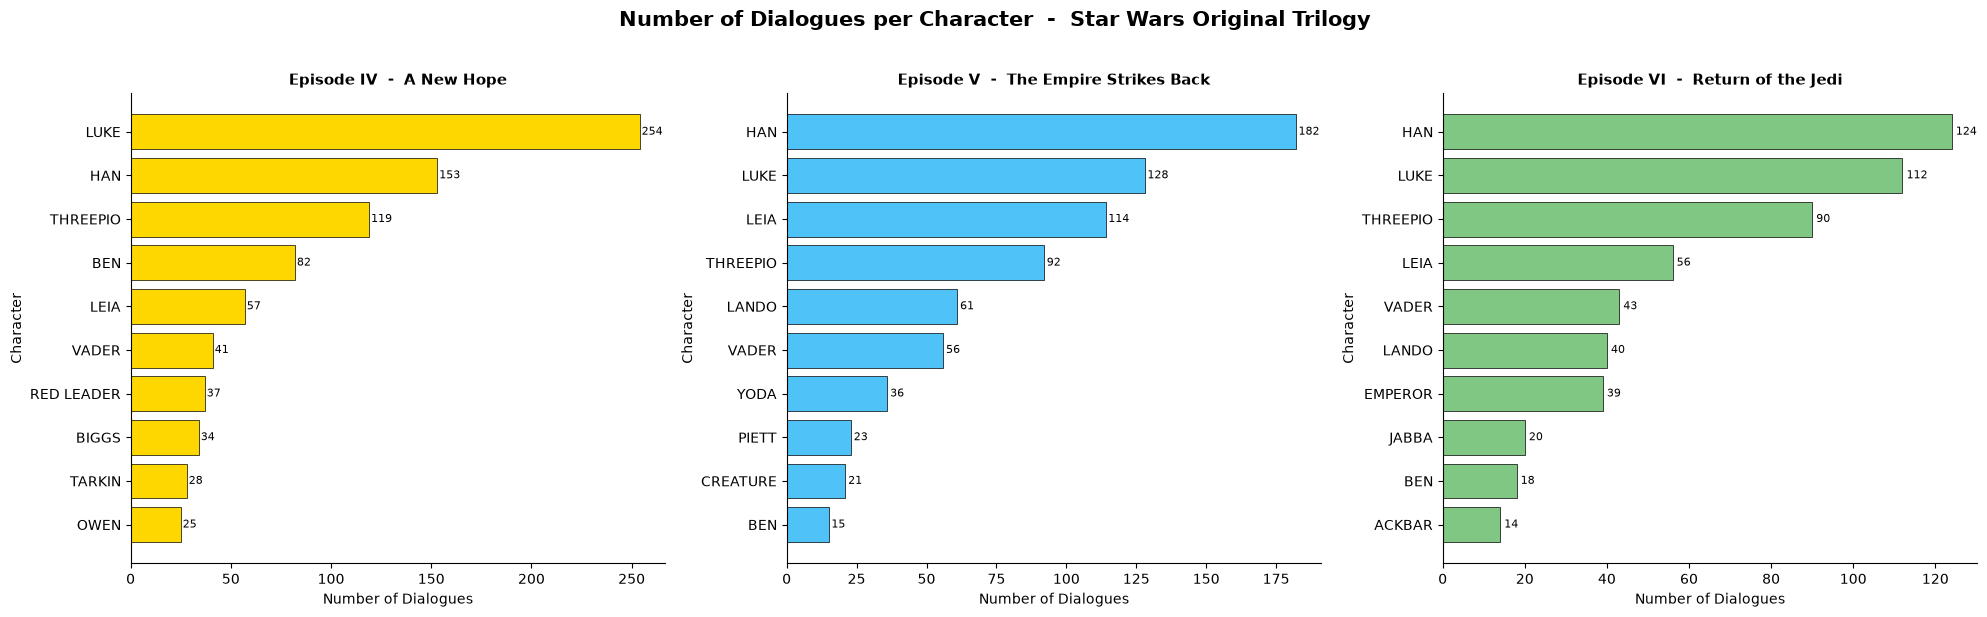

Plot saved.


In [4]:
# ── A2  -  Bar plots: dialogues per character per episode ──────────────────
colors = ['#FFD700', '#4FC3F7', '#81C784']  # gold, blue, green

fig, axes = plt.subplots(1, 3, figsize=(20, 6))
fig.suptitle('Number of Dialogues per Character  -  Star Wars Original Trilogy',
             fontsize=15, fontweight='bold', y=1.02)

for ax, (title, df), color in zip(axes, episodes.items(), colors):
    top = df['character'].value_counts().head(TOP_N)
    bars = ax.barh(top.index[::-1], top.values[::-1], color=color, edgecolor='black', linewidth=0.5)
    ax.set_title(title, fontsize=11, fontweight='bold')
    ax.set_xlabel('Number of Dialogues')
    ax.set_ylabel('Character')
    # Add value labels
    for bar in bars:
        w = bar.get_width()
        ax.text(w + 1, bar.get_y() + bar.get_height()/2,
                str(int(w)), va='center', ha='left', fontsize=8)
    ax.spines[['top', 'right']].set_visible(False)

plt.tight_layout()
plt.savefig('A2_dialogues_per_character.png', dpi=150, bbox_inches='tight')
plt.show()
print('Plot saved.')

### A3  -  Add Episode Column & Concatenate into One Dataset

In [5]:
ep4['episode'] = 'Episode IV'
ep5['episode'] = 'Episode V'
ep6['episode'] = 'Episode VI'

df_all = pd.concat([ep4, ep5, ep6], ignore_index=True)

print('Combined dataset shape:', df_all.shape)
df_all.head(10)

Combined dataset shape: (2523, 3)


,character,dialogue,episode
0,THREEPIO,Did you hear that? They've shut down the main...,Episode IV
1,THREEPIO,We're doomed!,Episode IV
2,THREEPIO,There'll be no escape for the Princess this time.,Episode IV
3,THREEPIO,What's that?,Episode IV
4,THREEPIO,I should have known better than to trust the l...,Episode IV
5,LUKE,Hurry up! Come with me! What are you waiting...,Episode IV
6,THREEPIO,"Artoo! Artoo-Detoo, where are you?",Episode IV
7,THREEPIO,At last! Where have you been?,Episode IV
8,THREEPIO,They're heading in this direction. What are we...,Episode IV
9,THREEPIO,"Wait a minute, where are you going?",Episode IV


In [6]:
# Quick sanity check
print('Dialogues per episode:')
print(df_all['episode'].value_counts())
print(f'\nTotal unique characters: {df_all["character"].nunique()}')
print('\nSample rows:')
df_all.sample(5, random_state=42)

Dialogues per episode:
episode
Episode IV    1010
Episode V      839
Episode VI     674
Name: count, dtype: int64

Total unique characters: 129

Sample rows:


,character,dialogue,episode
1927,HAN,Where am I?,Episode VI
296,LUKE,These are the same Jawas that sold us Artoo an...,Episode IV
485,LUKE,Maybe they know what happened.,Episode IV
211,OWEN,Uh? Did he take those two new droids with him?,Episode IV
479,LUKE,What do you mean? Where is it?,Episode IV


### A4 & A5  -  Word Frequency Distribution (Raw Text)

In [7]:
# ── Tokenise all dialogues (raw, no cleaning yet) ─────────────────────────
all_text_raw = ' '.join(df_all['dialogue'].dropna().astype(str).tolist())
tokens_raw   = word_tokenize(all_text_raw)

# Keep only alphabetic tokens for a cleaner distribution
tokens_raw_alpha = [w for w in tokens_raw if w.isalpha()]

fdist_raw = FreqDist(tokens_raw_alpha)

print(f'Total tokens (alphabetic): {len(tokens_raw_alpha):,}')
print(f'Unique tokens: {fdist_raw.B():,}')
print('\nTop 20 most frequent words:')
for word, freq in fdist_raw.most_common(20):
    print(f'  {word:<15} {freq}')

Total tokens (alphabetic): 25,622
Unique tokens: 3,138

Top 20 most frequent words:
  I               983
  you             809
  the             799
  to              642
  a               415
  of              345
  it              308
  is              277
  be              244
  You             244
  your            243
  in              233
  do              232
  on              228
  have            218
  that            216
  me              214
  this            197
  and             191
  for             190


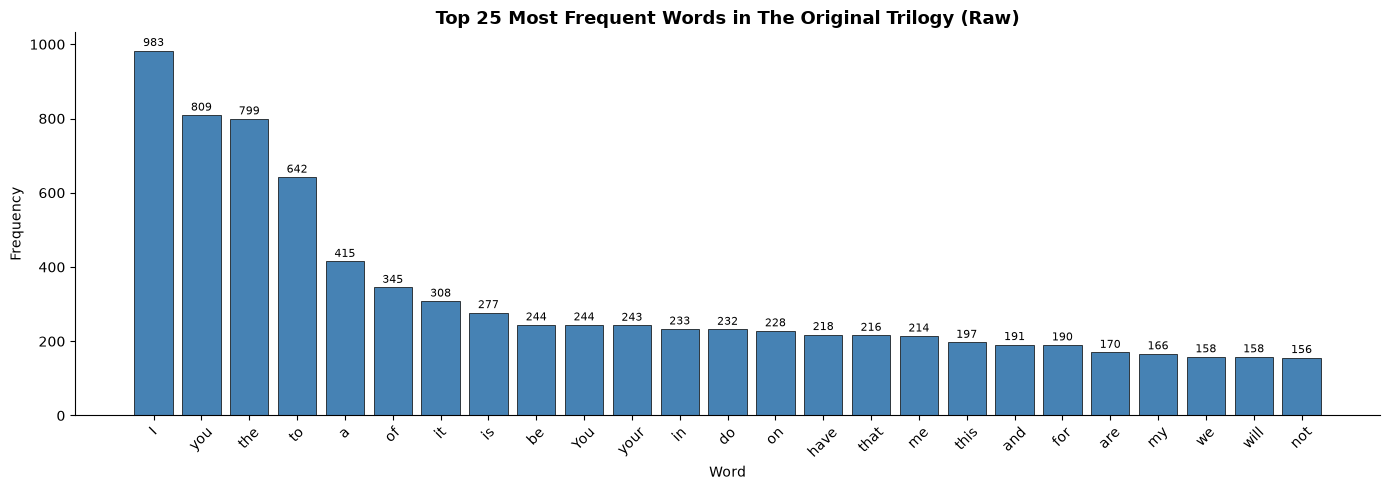

Plot saved.


In [8]:
# ── A5  -  Frequency Distribution Plot (raw) ───────────────────────────────
TOPW = 25
top_words_raw  = [w for w, _ in fdist_raw.most_common(TOPW)]
top_counts_raw = [fdist_raw[w] for w in top_words_raw]

fig, ax = plt.subplots(figsize=(14, 5))
bars = ax.bar(top_words_raw, top_counts_raw, color='steelblue', edgecolor='black', linewidth=0.5)
ax.set_title(f'Top {TOPW} Most Frequent Words in The Original Trilogy (Raw)',
             fontsize=13, fontweight='bold')
ax.set_xlabel('Word')
ax.set_ylabel('Frequency')
ax.tick_params(axis='x', rotation=45)
for bar in bars:
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 5,
            str(int(bar.get_height())), ha='center', va='bottom', fontsize=8)
ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout()
plt.savefig('A5_freq_dist_raw.png', dpi=150, bbox_inches='tight')
plt.show()
print('Plot saved.')

### A6  -  Text Pre-processing (NLTK)

In [9]:
# ── Pre-processing pipeline ───────────────────────────────────────────────
stop_words  = set(stopwords.words('english'))
lemmatizer  = WordNetLemmatizer()

def preprocess(text):
    """
    1. Lowercase
    2. Remove punctuation / special characters (keep letters only)
    3. Tokenise
    4. Remove stopwords
    5. Lemmatise
    Returns a list of cleaned tokens.
    """
    text  = str(text).lower()                          # lowercase
    text  = re.sub(r"[^a-z\s]", ' ', text)             # remove non-alpha
    tokens = word_tokenize(text)                        # tokenise
    tokens = [t for t in tokens if t not in stop_words # remove stopwords
              and len(t) > 1]                           # remove single chars
    tokens = [lemmatizer.lemmatize(t) for t in tokens] # lemmatise
    tokens = [t for t in tokens if len(t) > 1]  # re-filter: lemmatisation can produce single chars (e.g. 'us' -> 'u')
    return tokens

# Apply to the full dataset
df_all['new_script'] = df_all['dialogue'].apply(preprocess)

print('Pre-processing complete.')
print('\nSample rows (dialogue → new_script):')
df_all[['character', 'episode', 'dialogue', 'new_script']].sample(5, random_state=7)

Pre-processing complete.

Sample rows (dialogue → new_script):


,character,episode,dialogue,new_script
1187,RIEEKAN,Episode V,Their primary target will be the power generat...,"[primary, target, power, generator, prepare, o..."
1084,THREEPIO,Episode V,Don't say thing like that! Of course we'll see...,"[say, thing, like, course, see, master, luke, ..."
1213,LUKE,Episode V,"Wedge, I've lost my gunner. You'll have to mak...","[wedge, lost, gunner, make, shot, cover, set, ..."
1974,HAN,Episode VI,How are we doing?,[]
927,WEDGE,Episode IV,This is Red Two. Flying towards you.,"[red, two, flying, towards]"


### A7  -  Frequency Distribution After Pre-processing

In [10]:
# ── Flatten all cleaned tokens ────────────────────────────────────────────
from itertools import chain
tokens_clean = list(chain.from_iterable(df_all['new_script'].tolist()))

fdist_clean = FreqDist(tokens_clean)

print(f'Total tokens after pre-processing: {len(tokens_clean):,}')
print(f'Unique tokens: {fdist_clean.B():,}')
print('\nTop 20 most frequent words (cleaned):')
for word, freq in fdist_clean.most_common(20):
    print(f'  {word:<15} {freq}')

Total tokens after pre-processing: 12,285
Unique tokens: 2,449

Top 20 most frequent words (cleaned):
  luke            137
  get             130
  going           121
  come            113
  right           113
  oh              113
  know            110
  see             95
  well            92
  sir             91
  go              89
  artoo           85
  one             84
  got             81
  good            80
  yes             78
  take            75
  ship            74
  back            73
  like            69


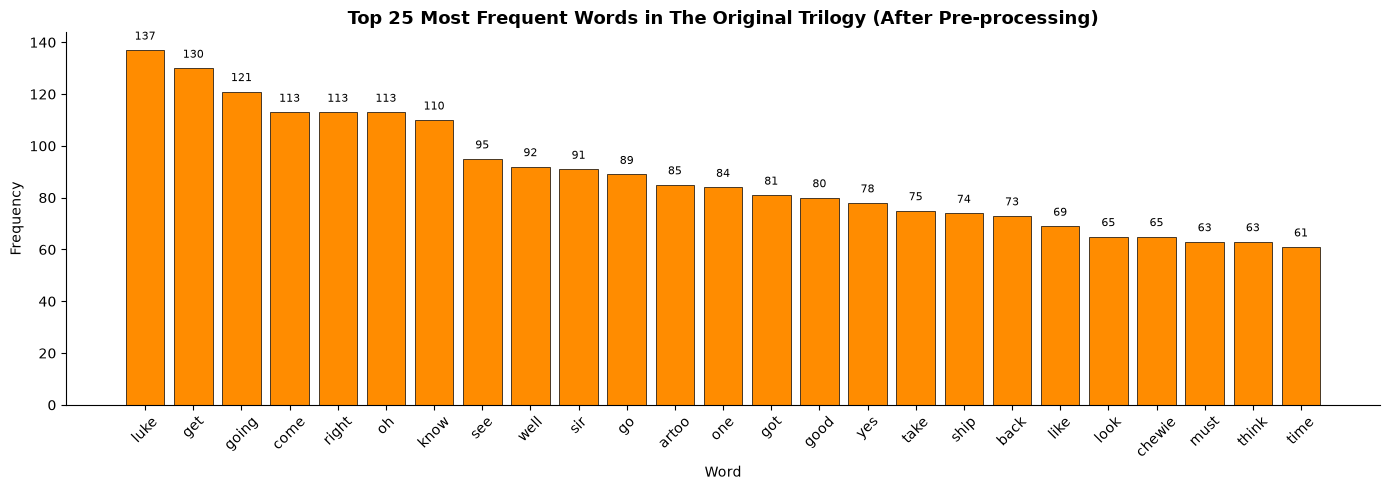

Plot saved.

--- Observation ---
Before pre-processing the top words are largely stopwords (the, I, you, it, a, ...).
After pre-processing, meaningful content words emerge: luke, get, going, come, right, know, artoo, han, ...


In [11]:
# ── A7  -  Frequency Distribution Plot (cleaned) ───────────────────────────
top_words_clean  = [w for w, _ in fdist_clean.most_common(TOPW)]
top_counts_clean = [fdist_clean[w] for w in top_words_clean]

fig, ax = plt.subplots(figsize=(14, 5))
bars = ax.bar(top_words_clean, top_counts_clean, color='darkorange', edgecolor='black', linewidth=0.5)
ax.set_title(f'Top {TOPW} Most Frequent Words in The Original Trilogy (After Pre-processing)',
             fontsize=13, fontweight='bold')
ax.set_xlabel('Word')
ax.set_ylabel('Frequency')
ax.tick_params(axis='x', rotation=45)
for bar in bars:
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 3,
            str(int(bar.get_height())), ha='center', va='bottom', fontsize=8)
ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout()
plt.savefig('A7_freq_dist_clean.png', dpi=150, bbox_inches='tight')
plt.show()
print('Plot saved.')

print('\n--- Observation ---')
print('Before pre-processing the top words are largely stopwords (the, I, you, it, a, ...).')
print('After pre-processing, meaningful content words emerge: luke, get, going, come, right, know, artoo, han, ...')

### A8  -  Word Clouds for Darth Vader and Yoda

In [12]:
# ── Helper: get cleaned text for a character ─────────────────────────────
def get_character_text(character_name):
    rows = df_all[df_all['character'].str.upper() == character_name.upper()]
    tokens = list(chain.from_iterable(rows['new_script'].tolist()))
    return ' '.join(tokens)

vader_text = get_character_text('VADER')
yoda_text  = get_character_text('YODA')

print(f'Vader  -  {len(vader_text.split()):,} tokens')
print(f'Yoda   -  {len(yoda_text.split()):,} tokens')

Vader  -  691 tokens
Yoda   -  373 tokens


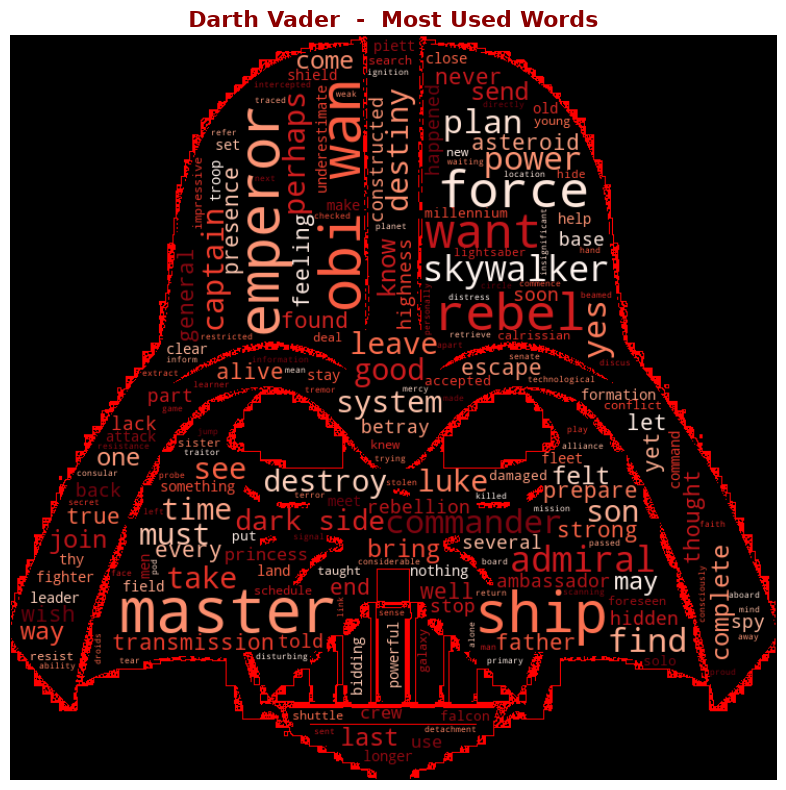

Vader word cloud saved.


In [13]:
# ── Load masks ────────────────────────────────────────────────────────────
vader_mask = np.array(Image.open(os.path.join(masks_dir, 'vader.jpg')))
yoda_mask  = np.array(Image.open(os.path.join(masks_dir, 'yoda.png')))

# ── Darth Vader Word Cloud ─────────────────────────────────────────────────
wc_vader = WordCloud(
    mask=vader_mask,
    background_color='black',
    colormap='Reds',
    max_words=200,
    contour_width=1,
    contour_color='red'
).generate(vader_text)

fig, ax = plt.subplots(figsize=(10, 8))
ax.imshow(wc_vader, interpolation='bilinear')
ax.axis('off')
ax.set_title("Darth Vader  -  Most Used Words", fontsize=16, fontweight='bold', color='darkred')
plt.tight_layout()
plt.savefig('A8_wordcloud_vader.png', dpi=150, bbox_inches='tight', facecolor='black')
plt.show()
print('Vader word cloud saved.')

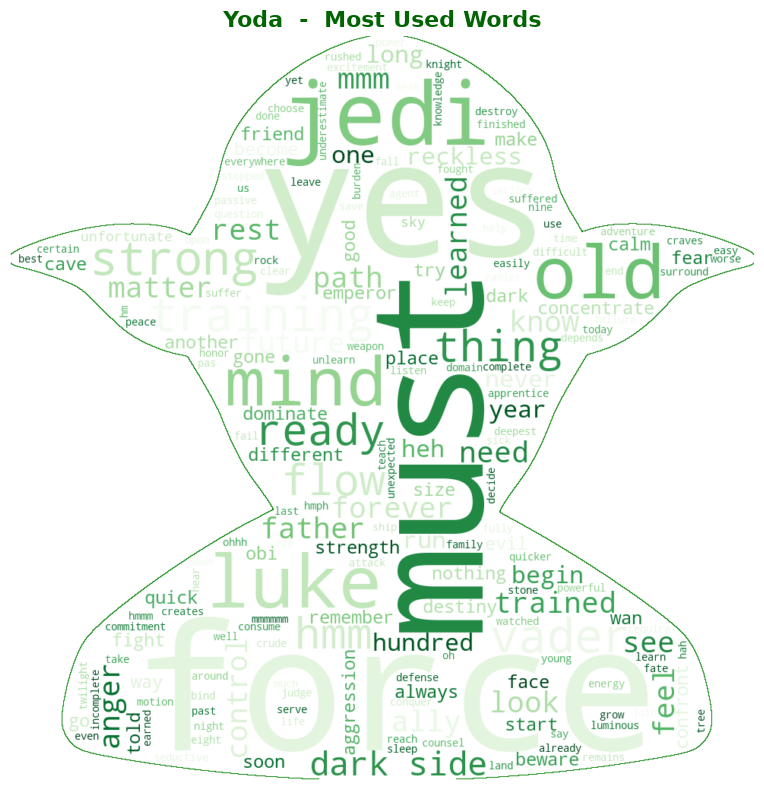

Yoda word cloud saved.


In [14]:
# ── Yoda Word Cloud ────────────────────────────────────────────────────────
wc_yoda = WordCloud(
    mask=yoda_mask,
    background_color='white',
    colormap='Greens',
    max_words=200,
    contour_width=1,
    contour_color='green'
).generate(yoda_text)

fig, ax = plt.subplots(figsize=(10, 8))
ax.imshow(wc_yoda, interpolation='bilinear')
ax.axis('off')
ax.set_title("Yoda  -  Most Used Words", fontsize=16, fontweight='bold', color='darkgreen')
plt.tight_layout()
plt.savefig('A8_wordcloud_yoda.png', dpi=150, bbox_inches='tight')
plt.show()
print('Yoda word cloud saved.')

### A9  -  TF-IDF: Most Relevant Words in The Original Trilogy

In [15]:
# ── TF-IDF treats each row (dialogue line) as a document ─────────────────
# Use the pre-processed tokens joined back into a string
df_all['new_script_str'] = df_all['new_script'].apply(lambda tokens: ' '.join(tokens))

# Filter out empty rows
corpus = df_all['new_script_str'][df_all['new_script_str'].str.strip() != ''].tolist()

tfidf = TfidfVectorizer(max_features=5000, ngram_range=(1, 1))
tfidf_matrix = tfidf.fit_transform(corpus)

# Mean TF-IDF score across all documents for each term
mean_tfidf = np.array(tfidf_matrix.mean(axis=0)).flatten()
feature_names = np.array(tfidf.get_feature_names_out())

# Sort by importance
top_indices = mean_tfidf.argsort()[::-1][:30]
top_tfidf_words  = feature_names[top_indices]
top_tfidf_scores = mean_tfidf[top_indices]

print('Top 30 most relevant words by mean TF-IDF score:')
for word, score in zip(top_tfidf_words, top_tfidf_scores):
    print(f'  {word:<20} {score:.6f}')

Top 30 most relevant words by mean TF-IDF score:
  luke                 0.019192
  come                 0.018416
  right                0.018009
  going                0.017065
  oh                   0.016321
  get                  0.016276
  yes                  0.016125
  know                 0.015185
  see                  0.014531
  go                   0.013884
  sir                  0.013728
  artoo                0.013228
  chewie               0.012055
  well                 0.011187
  got                  0.010960
  good                 0.010782
  one                  0.010195
  look                 0.010025
  back                 0.009950
  take                 0.009751
  let                  0.009433
  think                0.009344
  like                 0.008841
  ship                 0.008611
  father               0.008528
  help                 0.008054
  wait                 0.008040
  master               0.007776
  vader                0.007488
  way                  

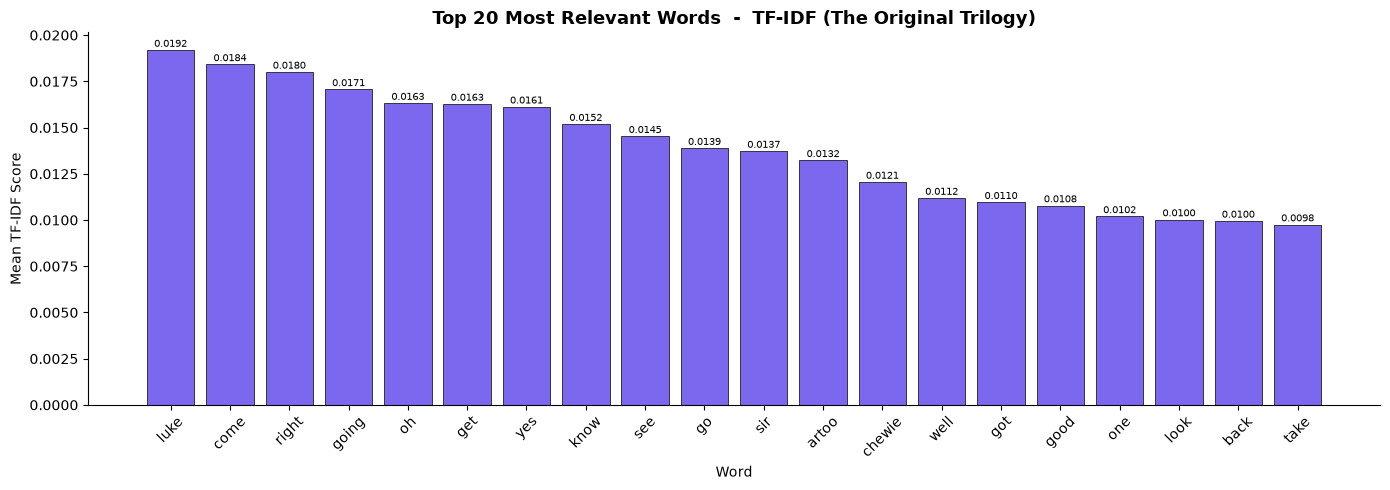

TF-IDF plot saved.

--- Interpretation ---
TF-IDF highlights words that are distinctive to individual dialogue lines
(rather than just the most frequent overall). These are the words that carry
the most unique, contextual meaning across the trilogy, filtering out words
that appear uniformly in every dialogue.



In [16]:
# ── TF-IDF bar chart ──────────────────────────────────────────────────────
TOPW_TFIDF = 20
fig, ax = plt.subplots(figsize=(14, 5))
bars = ax.bar(top_tfidf_words[:TOPW_TFIDF], top_tfidf_scores[:TOPW_TFIDF],
              color='mediumslateblue', edgecolor='black', linewidth=0.5)
ax.set_title(f'Top {TOPW_TFIDF} Most Relevant Words  -  TF-IDF (The Original Trilogy)',
             fontsize=13, fontweight='bold')
ax.set_xlabel('Word')
ax.set_ylabel('Mean TF-IDF Score')
ax.tick_params(axis='x', rotation=45)
ax.yaxis.set_major_formatter(mticker.FormatStrFormatter('%.4f'))
for bar in bars:
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.00005,
            f'{bar.get_height():.4f}', ha='center', va='bottom', fontsize=7)
ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout()
plt.savefig('A9_tfidf.png', dpi=150, bbox_inches='tight')
plt.show()
print('TF-IDF plot saved.')

print("""
--- Interpretation ---
TF-IDF highlights words that are distinctive to individual dialogue lines
(rather than just the most frequent overall). These are the words that carry
the most unique, contextual meaning across the trilogy, filtering out words
that appear uniformly in every dialogue.
""")

### A10  -  Sentiment Analysis with VADER

In [17]:
# ── Apply VADER to each dialogue line (use original dialogue, not cleaned) ─
analyzer = SentimentIntensityAnalyzer()

def get_sentiment_scores(text):
    scores = analyzer.polarity_scores(str(text))
    return scores['neg'], scores['neu'], scores['pos'], scores['compound']

df_all[['neg', 'neu', 'pos', 'compound']] = df_all['dialogue'].apply(
    lambda x: pd.Series(get_sentiment_scores(x))
)

# Classify each line
def classify_sentiment(compound):
    if compound >= 0.05:  return 'Positive'
    elif compound <= -0.05: return 'Negative'
    else:                 return 'Neutral'

df_all['sentiment'] = df_all['compound'].apply(classify_sentiment)

print('Sentiment distribution across all dialogues:')
print(df_all['sentiment'].value_counts())
print(f"\nOverall mean compound score: {df_all['compound'].mean():.4f}")

Sentiment distribution across all dialogues:
sentiment
Neutral     1178
Positive     794
Negative     551
Name: count, dtype: int64

Overall mean compound score: 0.0472


Mean compound sentiment score per episode:
episode
Episode IV    0.012079
Episode V     0.076842
Episode VI    0.062848


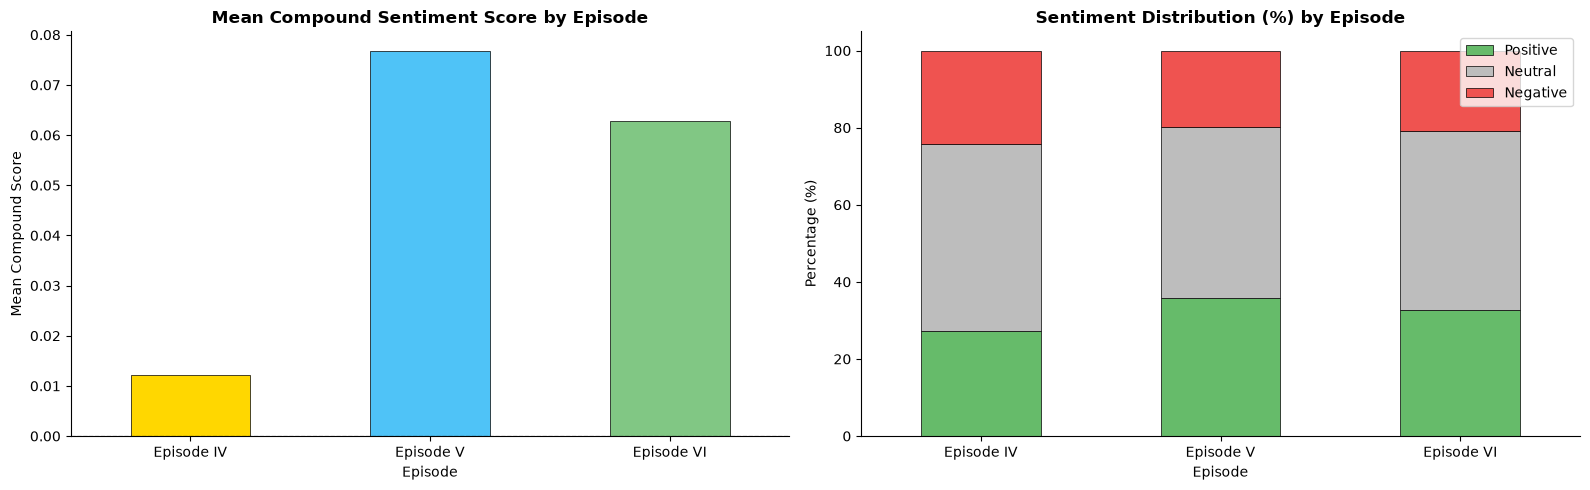

Episode sentiment plots saved.


In [18]:
# ── Sentiment by episode ──────────────────────────────────────────────────
print('Mean compound sentiment score per episode:')
ep_sentiment = df_all.groupby('episode')['compound'].mean().sort_index()
print(ep_sentiment.to_string())

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# Subplot 1: mean compound per episode
ep_sentiment.plot(kind='bar', ax=axes[0], color=['#FFD700', '#4FC3F7', '#81C784'],
                  edgecolor='black', linewidth=0.5)
axes[0].axhline(0, color='black', linewidth=0.8, linestyle='--')
axes[0].set_title('Mean Compound Sentiment Score by Episode', fontweight='bold')
axes[0].set_xlabel('Episode')
axes[0].set_ylabel('Mean Compound Score')
axes[0].tick_params(axis='x', rotation=0)
axes[0].spines[['top', 'right']].set_visible(False)

# Subplot 2: stacked sentiment distribution per episode
ep_sent_pct = (
    df_all.groupby(['episode', 'sentiment']).size()
    .unstack(fill_value=0)
    .apply(lambda row: row / row.sum() * 100, axis=1)
)
ep_sent_pct[['Positive', 'Neutral', 'Negative']].plot(
    kind='bar', stacked=True, ax=axes[1],
    color=['#66BB6A', '#BDBDBD', '#EF5350'],
    edgecolor='black', linewidth=0.5
)
axes[1].set_title('Sentiment Distribution (%) by Episode', fontweight='bold')
axes[1].set_xlabel('Episode')
axes[1].set_ylabel('Percentage (%)')
axes[1].tick_params(axis='x', rotation=0)
axes[1].legend(loc='upper right')
axes[1].spines[['top', 'right']].set_visible(False)

plt.tight_layout()
plt.savefig('A10_sentiment_episodes.png', dpi=150, bbox_inches='tight')
plt.show()
print('Episode sentiment plots saved.')

In [19]:
# ── Sentiment by key character ────────────────────────────────────────────
KEY_CHARACTERS = [
    # Dark Side
    'VADER', 'EMPEROR', 'TARKIN',
    # Light Side
    'LUKE', 'LEIA', 'HAN', 'YODA', 'BEN'
]

char_sentiment = (
    df_all[df_all['character'].isin(KEY_CHARACTERS)]
    .groupby('character')[['neg', 'neu', 'pos', 'compound']]
    .mean()
    .round(4)
)
char_sentiment['dialogue_count'] = (
    df_all[df_all['character'].isin(KEY_CHARACTERS)]
    .groupby('character').size()
)
char_sentiment = char_sentiment.reindex(KEY_CHARACTERS).dropna()
# Note: Obi-Wan Kenobi is named 'BEN' in the episode scripts

print('Sentiment scores for key characters:')
print(char_sentiment.to_string())

Sentiment scores for key characters:
              neg     neu     pos  compound  dialogue_count
character                                                  
VADER      0.0764  0.7890  0.1346    0.0333             140
EMPEROR    0.1193  0.6983  0.1824    0.1063              44
TARKIN     0.0985  0.6616  0.2399    0.0312              28
LUKE       0.0558  0.8298  0.1144    0.0567             494
LEIA       0.0769  0.8121  0.1110    0.0439             227
HAN        0.0628  0.7956  0.1416    0.1068             459
YODA       0.1015  0.7771  0.1213    0.0239              49
BEN        0.0729  0.8311  0.0961    0.0536             115


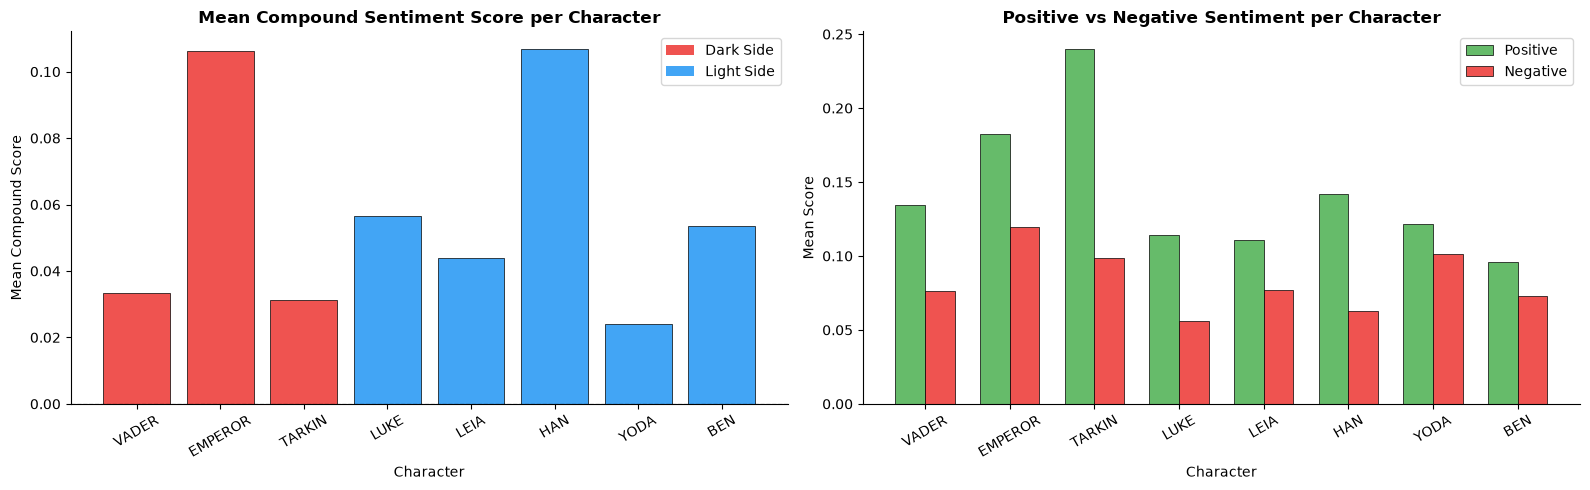

Character sentiment plots saved.


In [20]:
# ── Character sentiment comparison plot ──────────────────────────────────
# Colour by side: red = Dark Side, blue = Light Side
dark_side  = ['VADER', 'EMPEROR', 'TARKIN']
light_side = ['LUKE', 'LEIA', 'HAN', 'YODA', 'BEN']

char_df = char_sentiment.reset_index()
char_df = char_df.dropna(subset=['compound'])

colors_char = ['#EF5350' if c in dark_side else '#42A5F5' for c in char_df['character']]

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# Mean compound score
bars = axes[0].bar(char_df['character'], char_df['compound'],
                   color=colors_char, edgecolor='black', linewidth=0.5)
axes[0].axhline(0, color='black', linewidth=0.8, linestyle='--')
axes[0].set_title('Mean Compound Sentiment Score per Character', fontweight='bold')
axes[0].set_xlabel('Character')
axes[0].set_ylabel('Mean Compound Score')
axes[0].tick_params(axis='x', rotation=30)
axes[0].spines[['top', 'right']].set_visible(False)
# Legend
from matplotlib.patches import Patch
legend_elements = [Patch(facecolor='#EF5350', label='Dark Side'),
                   Patch(facecolor='#42A5F5', label='Light Side')]
axes[0].legend(handles=legend_elements)

# Neg / Pos breakdown
x = np.arange(len(char_df))
width = 0.35
axes[1].bar(x - width/2, char_df['pos'], width, label='Positive', color='#66BB6A', edgecolor='black', linewidth=0.5)
axes[1].bar(x + width/2, char_df['neg'], width, label='Negative', color='#EF5350', edgecolor='black', linewidth=0.5)
axes[1].set_title('Positive vs Negative Sentiment per Character', fontweight='bold')
axes[1].set_xlabel('Character')
axes[1].set_ylabel('Mean Score')
axes[1].set_xticks(x)
axes[1].set_xticklabels(char_df['character'], rotation=30)
axes[1].legend()
axes[1].spines[['top', 'right']].set_visible(False)

plt.tight_layout()
plt.savefig('A10_sentiment_characters.png', dpi=150, bbox_inches='tight')
plt.show()
print('Character sentiment plots saved.')

---
## Part B  -  Sentiment Analysis Insights

### Do Dark Side characters differ from Light Side characters in sentiment?

The VADER sentiment analysis reveals a more nuanced picture than the Star Wars narrative might suggest, and highlights some important limitations of automated sentiment tools when applied to scripted film dialogue.

**Dark Side characters (Vader, Emperor, Tarkin)**  
Contrary to what might be expected, none of the Dark Side characters score negatively on the compound scale. Darth Vader scores +0.033 and Tarkin +0.031  -  both marginally positive, sitting closest to neutral of all characters analysed. The Emperor, however, scores +0.106, one of the highest compound scores in the group. This is counterintuitive given his role as the embodiment of evil, but VADER struggles with the type of cold, authoritative language these characters use  -  declarative commands and formal speech do not carry the emotional charge that sentiment lexicons are trained to detect. Words such as "power", "strong", and "master" may also inadvertently register as positive.

**Light Side characters (Luke, Leia, Han, Yoda, Ben/Obi-Wan)**  
Light Side characters also score slightly positive overall, but the differences within this group are notable. Han Solo scores the highest compound of all characters (+0.107), consistent with his expressive, emotionally varied dialogue. Luke (+0.057), Ben/Obi-Wan (+0.054), and Leia (+0.044) follow. Ben's score aligns with his calm, measured speech throughout the trilogy. Yoda, surprisingly, records the *lowest* compound score of all characters analysed (+0.024)  -  lower even than Vader and Tarkin. Yoda's terse, inverted speech patterns and frequent use of negative constructions (e.g. *"Do or do not, there is no try"*) likely confuse VADER's scoring.

**Episode-level trend**  
Episode IV (A New Hope) shows the lowest mean compound score (0.012), while Episode V (The Empire Strikes Back) records the highest (0.077). This is counterintuitive given Episode V's reputation as the darkest film, but may be explained by the Rebel characters' use of rallying and encouraging language even under pressure. Episode VI sits in between (0.063).

**Conclusion**  
The sentiment analysis does not produce a clean Dark Side vs. Light Side split, which is itself an instructive finding. The results demonstrate a key limitation of lexicon-based tools like VADER: they are calibrated for conversational and social-media text, not scripted cinematic dialogue. Formal, declarative, or stylistically unusual speech (Yoda's syntax, Vader's commands, the Emperor's manipulation) does not map well onto standard sentiment categories. A more accurate analysis would require a domain-specific model trained on film scripts. That said, the overall compound scores are low and close to neutral across all characters, reflecting that much of the trilogy's dialogue is action-driven and descriptive rather than overtly emotional.


---
## Part C  -  AI-Age Reflection

##### 1. How did AI assist your analytical process?

AI was used sparingly as a reference tool during this lab  -  primarily to look up syntax for specific library functions (e.g., WordCloud parameters, NLTK lemmatiser usage) when the documentation was unclear. The core analytical decisions  -  choosing which preprocessing steps to apply, selecting the right visualisation types, and interpreting the sentiment results  -  were made independently. AI did not drive the direction of the analysis; it served a similar role to searching Stack Overflow or reading documentation.

##### 2. Did you critically evaluate AI-generated outputs?

Yes, any AI-suggested code snippets were reviewed carefully before use. For example, a suggested approach to file parsing needed to be adjusted because the quoted-string format of the episode files required a custom regex solution rather than a generic CSV reader. VADER's suitability for scripted film dialogue (rather than modern social-media text) was also considered  -  its scores were treated as indicative rather than ground truth, and conclusions were cross-checked against a manual reading of key character dialogues to ensure they made intuitive sense.

##### 3. What are the risks of relying blindly on AI in business analytics?

Over-reliance on AI in business analytics can introduce several risks:

1. **False confidence in outputs.** AI-generated code or insights can look polished and authoritative even when the underlying logic is flawed, making errors harder to spot.
2. **Domain mismatch.** Models trained on one type of text (e.g., tweets) may not generalise to another (e.g., legal contracts or film scripts), producing misleading results if applied without validation.
3. **Accountability gap.** When a decision is made purely on AI output without human review, there is no clear reasoning chain to audit if something goes wrong.
4. **Skill erosion.** If analysts outsource thinking to AI tools routinely, they may lose the foundational understanding needed to catch errors or ask the right questions.

The appropriate role for AI is as a productivity aid, not a replacement for analytical judgement. Human oversight remains essential at every stage of a business analytics workflow.
